# CLFG modeling site and HRRR-AK grid

A close-up of the CLFG modeling point near Mendenhall Glacier, with a translucent
HRRR-AK 2 m air temperature overlay on Esri World Imagery. Each outlined
quadrilateral is one native HRRR-AK grid cell.

Run in the JIF snow modeling environment. The first run downloads imagery to
`data/basemaps/`. Set `JIF_GRIB` to change the local forecast file.

In [1]:
import hashlib
import io
import json
import os
from pathlib import Path
from urllib.parse import urlencode
from urllib.request import urlopen

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
import pygrib
from pyproj import CRS, Transformer

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'jif_domain').is_dir())
FIGURES = ROOT / 'figures'
CACHE = ROOT / 'data/basemaps'
FIGURES.mkdir(exist_ok=True)

GRIB = Path(os.environ.get(
    'JIF_GRIB',
    '/hdd/snow_hydrology/hrrrak/icefield_domain/f567/WY2026/'
    'hrrr.20260525/hrrr.t12z.wrfsfcf06.ak.grib2',
))
UTM = 32608
to_utm = Transformer.from_crs(4326, UTM, always_xy=True)

clfg = dict(line.split(': ', 1) for line in
            (ROOT / 'sites/clfg/site_info.txt').read_text().splitlines() if line.strip())
lat, lon = (float(clfg[key].rsplit('(', 1)[1].rstrip(')')) for key in ('Latitude', 'Longitude'))
clfg_x, clfg_y = (value / 1000 for value in to_utm.transform(lon, lat))
west, east = np.floor(clfg_x) - 6, np.ceil(clfg_x) + 6
south, north = np.floor(clfg_y) - 4, np.ceil(clfg_y) + 10

## Satellite imagery

The image is requested in WGS 84 / UTM zone 8N from [Esri World Imagery](https://services.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer).

In [2]:
service = 'https://services.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer'
params = dict(
    bbox=','.join(str(int(km * 1000)) for km in (west, south, east, north)),
    bboxSR=UTM, imageSR=UTM, size=f'{int((east-west)*100)},{int((north-south)*100)}',
    format='jpg', f='json',
)
cache_key = hashlib.sha256(urlencode(params).encode()).hexdigest()[:16]
image_path = CACHE / f'esri_{cache_key}.jpg'
metadata_path = CACHE / f'esri_{cache_key}.json'
if not (image_path.is_file() and metadata_path.is_file()):
    with urlopen(f'{service}/export?{urlencode(params)}', timeout=60) as response:
        metadata = json.load(response)
    if 'error' in metadata:
        raise RuntimeError(f'Esri World Imagery export failed: {metadata["error"]}')
    with urlopen(metadata['href'], timeout=60) as response:
        image_bytes = response.read()
    with Image.open(io.BytesIO(image_bytes)) as downloaded:
        downloaded.verify()
    CACHE.mkdir(parents=True, exist_ok=True)
    image_path.write_bytes(image_bytes)
    metadata_path.write_text(json.dumps(metadata, indent=2))

bounds = json.loads(metadata_path.read_text())['extent']
image_extent = [bounds[key] / 1000 for key in ('xmin', 'xmax', 'ymin', 'ymax')]
with Image.open(image_path) as cached:
    imagery = np.asarray(cached.convert('RGB'))

## Native HRRR-AK temperature grid

The default forecast is valid at 18:00 UTC on May 25, 2026, the date of the
CLFG snow-depth observation. Cell boundaries are calculated in the native
polar stereographic projection before conversion to UTM zone 8N.

In [3]:
if not GRIB.is_file():
    raise FileNotFoundError(f'{GRIB} is missing. Set JIF_GRIB to a local HRRR-AK GRIB2 file.')

with pygrib.open(str(GRIB)) as fields:
    temperature_field, = fields.select(shortName='2t', typeOfLevel='heightAboveGround', level=2)
    temperature = temperature_field.values - 273.15
    lat, lon = temperature_field.latlons()
    native = CRS.from_dict(temperature_field.projparams)
    dx, dy = temperature_field['DxInMetres'], temperature_field['DyInMetres']
    initialized, valid = temperature_field.analDate, temperature_field.validDate

to_native = Transformer.from_crs(4326, native, always_xy=True)
native_to_utm = Transformer.from_crs(native, UTM, always_xy=True)
center_x, center_y = to_native.transform(lon, lat)
ny, nx = temperature.shape
x = center_x[0, 0] + np.arange(nx) * np.copysign(dx, center_x[0, -1] - center_x[0, 0])
y = center_y[0, 0] + np.arange(ny) * np.copysign(dy, center_y[-1, 0] - center_y[0, 0])
if not (np.allclose(center_x, x[None, :], atol=2, rtol=0)
        and np.allclose(center_y, y[:, None], atol=2, rtol=0)):
    raise ValueError('Decoded coordinates do not match a regular native HRRR-AK grid.')

x_edges = x[0] + (np.arange(nx + 1) - 0.5) * np.copysign(dx, x[-1] - x[0])
y_edges = y[0] + (np.arange(ny + 1) - 0.5) * np.copysign(dy, y[-1] - y[0])
grid_x, grid_y = native_to_utm.transform(*np.meshgrid(x_edges, y_edges))
grid_x, grid_y = grid_x / 1000, grid_y / 1000

# Scale the colors to cells whose corner bounds intersect the map.
corners_x = [grid_x[:-1, :-1], grid_x[1:, :-1], grid_x[:-1, 1:], grid_x[1:, 1:]]
corners_y = [grid_y[:-1, :-1], grid_y[1:, :-1], grid_y[:-1, 1:], grid_y[1:, 1:]]
in_view = (
    (np.min(corners_x, axis=0) < east) & (np.max(corners_x, axis=0) > west)
    & (np.min(corners_y, axis=0) < north) & (np.max(corners_y, axis=0) > south)
)
visible = np.ma.masked_invalid(temperature[in_view])
if visible.count() == 0:
    raise ValueError('The selected GRIB has no valid temperatures in the map extent.')

## CLFG close-up

Glacier labels mark general locations. Reference locations come from the
[U.S. Census Bureau glacier inventory](https://tigerweb.geo.census.gov/tigerwebmain/Files/acs24/tigerweb_acs24_glaciers_us.html)
and the [Alaska State Library glacier index](https://library.alaska.gov/asp/alaska_glaciers.HTML).

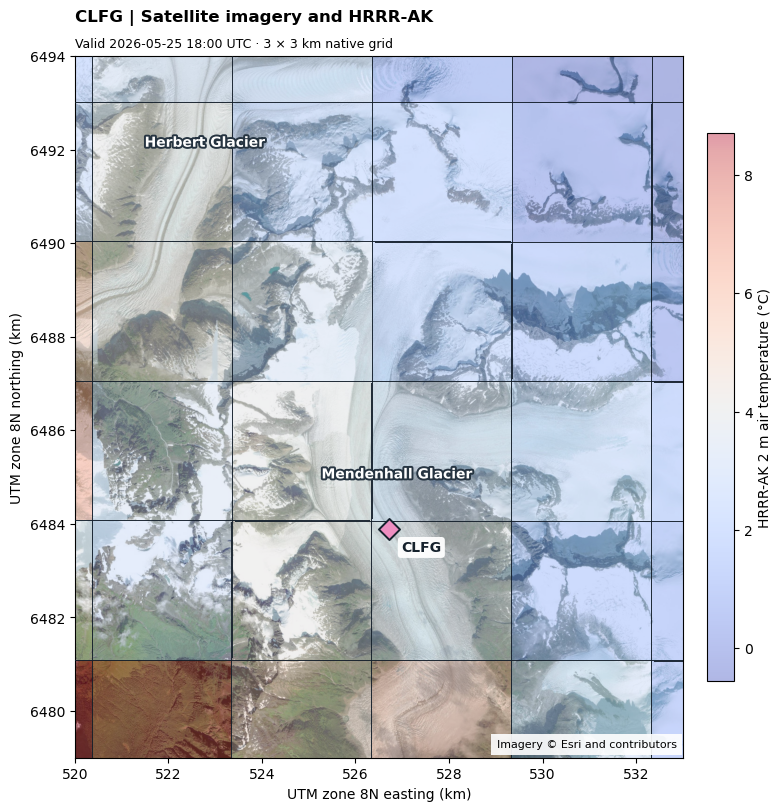

In [4]:
import matplotlib.patheffects as pe

fig, ax = plt.subplots(figsize=(9, 8), layout='constrained')
ax.imshow(imagery, extent=image_extent, origin='upper')
mesh = ax.pcolormesh(grid_x, grid_y, temperature, shading='flat', cmap='coolwarm',
                     alpha=0.40, vmin=visible.min(), vmax=visible.max(), zorder=2)
# Draw cell outlines separately to keep them legible over snow and rock.
outlines = ax.pcolormesh(grid_x, grid_y, temperature, shading='flat',
                         edgecolors=(0.08, 0.12, 0.17, 0.72), linewidth=0.7, zorder=3)
outlines.set_array(None)
outlines.set_facecolor('none')

glacier_labels = {
    'Mendenhall Glacier': (-134.538629, 58.5052512),
    'Herbert Glacier': (-(134 + 36/60 + 30/3600), 58 + 34/60 + 9/3600),
}
for name, (longitude, latitude) in glacier_labels.items():
    x_km, y_km = (value / 1000 for value in to_utm.transform(longitude, latitude))
    ax.text(x_km, y_km, name, ha='center', va='center', color='white',
            fontsize=10, weight='bold', zorder=4,
            path_effects=[pe.withStroke(linewidth=2.8, foreground='#263441')])

ax.scatter(clfg_x, clfg_y, marker='D', s=115, color='#ed8ec0',
           edgecolor='#15212c', linewidth=1.4, zorder=5)
ax.annotate('CLFG', (clfg_x, clfg_y), xytext=(9, -8), textcoords='offset points',
            va='top', fontsize=10, weight='bold', color='#15212c', zorder=6,
            bbox=dict(boxstyle='round,pad=0.25', fc='white', ec='none', alpha=0.95))

ax.set(xlim=(west, east), ylim=(south, north), aspect='equal',
       xlabel='UTM zone 8N easting (km)', ylabel='UTM zone 8N northing (km)')
ax.ticklabel_format(useOffset=False, style='plain')
ax.set_title('CLFG | Satellite imagery and HRRR-AK', loc='left', weight='bold', pad=25)
ax.text(0, 1.012, f'Valid {valid:%Y-%m-%d %H:%M} UTC · {dx/1000:g} × {dy/1000:g} km native grid',
        transform=ax.transAxes, fontsize=9)
ax.text(0.99, 0.015, 'Imagery © Esri and contributors', transform=ax.transAxes,
        ha='right', fontsize=8, bbox=dict(fc='white', ec='none', alpha=0.9), zorder=6)
fig.colorbar(mesh, ax=ax, shrink=0.78, pad=0.03, label='HRRR-AK 2 m air temperature (°C)')
fig.savefig(FIGURES / 'clfg_satellite_hrrrak.png', dpi=180)
plt.show()